# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** https://movielensrating.streamlit.app

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

I use this code to check the dataset's dimensions, data types, missing values, duplicate records, rating ranges, and unique users and movies.

In [2]:
# Your data checks here
# Check the dataset shape
print("Shape:", df.shape)

# Check column types
print("\nColumn types:")
print(df.dtypes.to_string())

# Check missing values
print("\nMissing values:")
print(df.isna().sum().to_string())

# Check duplicate rows
print("\nExact duplicate rows:",
      df.duplicated().sum())

# Check duplicate user-movie combinations
print("Duplicate (user_id, movie_id) pairs:",
      df.duplicated(["user_id", "movie_id"]).sum())

# Check numerical minimums and maximums
print("\nNumeric ranges:")
display(
    df.select_dtypes(include="number").agg(["min", "max"])
)

# Check unique users and movies
print("\nUnique users:", df["user_id"].nunique())
print("Unique movies:", df["movie_id"].nunique())

# Calculate overall average rating
print("Rating mean:",
      round(df["rating"].mean(), 5))

# Count movies with missing release years
print("Missing-year distinct movies:",
      df.loc[df["year"].isna(), "movie_id"].nunique())


Shape: (100000, 13)

Column types:
user_id          int64
movie_id         int64
rating           int64
timestamp       object
age              int64
gender          object
occupation      object
zip_code        object
title           object
year           float64
decade         float64
genres          object
rating_year      int64

Missing values:
user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0

Exact duplicate rows: 0
Duplicate (user_id, movie_id) pairs: 0

Numeric ranges:


,user_id,movie_id,rating,age,year,decade,rating_year
min,1,1,1,7,1922.0,1920.0,1997
max,943,1682,5,73,1998.0,1990.0,1998



Unique users: 943
Unique movies: 1682
Rating mean: 3.52986
Missing-year distinct movies: 5


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

I checked the dataset and found that it contains 100,000 rows and 13 columns, with 943 unique users and 1,682 unique movies. I noticed that the ratings range from 1 to 5, with an overall average of 3.52986, and that the movies were released between 1922 and 1998. I also found no duplicate rows or duplicate user-movie pairs, but 30 rows have missing release-year values, affecting five different movies. I decided to exclude these rows when analyzing movie release years while keeping their valid ratings for the other questions.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice:
- Why:

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice:
- Why:

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice:
- Why:

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice:
- Why:

## 1.2 Decide Before You Chart

### Q1. Genre Breakdown

**My choice:** I decided to count the number of unique movies in each genre instead of counting individual ratings. If a movie belongs to more than one genre, I will count it once in each genre.

**Why:** I chose this method because I want to see how movies are distributed across different genres. I think counting unique movies gives me a better understanding of the genre distribution without counting the same movie multiple times within one genre.

### Q2. Genre Satisfaction

**My choice:** I decided to calculate the average rating for each genre using all the individual user ratings. I will also check how many ratings each genre received.

**Why:** I chose this method because I want to find out which genres have the highest and lowest average ratings. I think checking the number of ratings is important because genres with fewer ratings might not give me reliable results.

### Q3. Ratings Over Time

**My choice:** I decided to use movie release years instead of the years when users submitted their ratings. I will calculate the average rating for each release year and exclude rows with missing release-year values.

**Why:** I chose this method because I want to see how ratings differ between movies released in different years. I also think checking the number of ratings for each year is important because some years might have fewer ratings than others.

### Q4. Best Movies

**My choice:** I decided to calculate the average rating for each movie and rank the movies that received at least 50 ratings. I will repeat the calculation using a minimum of 150 ratings. If movies have the same average rating, I will rank the one with more ratings first and then use alphabetical order if needed.

**Why:** I chose this method because I want to identify the highest-rated movies while making sure they received enough ratings. I think using minimum-rating requirements makes the comparison more meaningful because a movie with only a few high ratings might not be as reliable as one with many ratings.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

I use this code to split movies with multiple genres, count unique movies in each category, calculate percentages, and create a horizontal bar chart.

,movie_count,pct_of_1682_movies
genre,,
Drama,725,43.10
Comedy,505,30.02
Action,251,14.92
Thriller,251,14.92
Romance,247,14.68
Adventure,135,8.03
Children,122,7.25
Crime,109,6.48
Sci-Fi,101,6.00


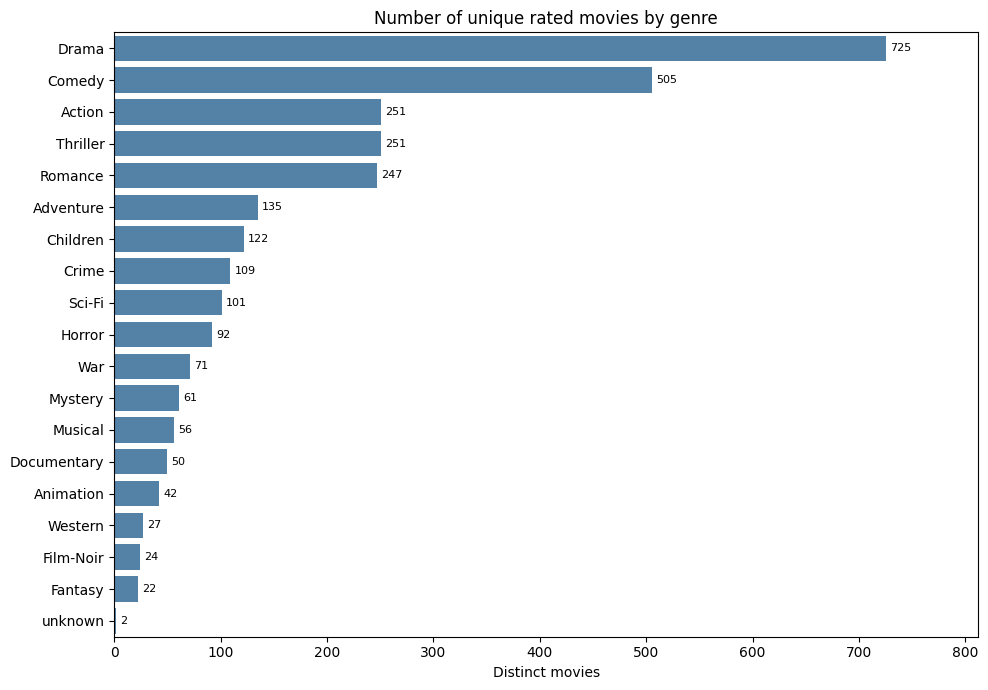

In [3]:
# Q1: One unique movie per movie_id
# with its full set of genres

movies = df[
    ["movie_id", "title", "genres", "year"]
].drop_duplicates("movie_id")

# Split multiple genres into individual rows
movie_genres = movies.assign(
    genre=movies["genres"].str.split("|", regex=False)
).explode("genre")

# Count unique movies by genre
q1 = (
    movie_genres.groupby("genre")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("movie_count")
    .to_frame()
)

# Calculate percentage of all movies
q1["pct_of_1682_movies"] = (
    100 * q1["movie_count"] / len(movies)
).round(2)

# Display results
display(q1)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    data=q1.reset_index(),
    x="movie_count",
    y="genre",
    color="steelblue",
    ax=ax
)

ax.set(
    title="Number of unique rated movies by genre",
    xlabel="Distinct movies",
    ylabel=""
)

# Add exact movie counts to the bars
for i, value in enumerate(q1["movie_count"]):
    ax.text(
        value + 4,
        i,
        str(value),
        va="center",
        fontsize=8
    )

ax.set_xlim(0, q1["movie_count"].max() * 1.12)

plt.tight_layout()
plt.show()


**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

I found that Drama is the most common genre, with 725 movies (43.10%), followed by Comedy with 505 movies (30.02%). Action and Thriller each have 251 movies (14.92%), while Romance has 247 movies (14.68%). I also noticed that unknown has only 2 movies, Fantasy has 22, and Film-Noir has 24, making them the least common categories. I counted unique movies in each genre, so a movie belonging to multiple genres is included in each relevant category.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

I calculate the average rating for every genre along with the number of ratings and unique movies, and I visualize those results using a dot plot.

,mean_rating,n_ratings,n_movies
genre,,,
Film-Noir,3.922,1733,24
War,3.816,9398,71
Drama,3.687,39895,725
Documentary,3.673,758,50
Mystery,3.638,5245,61
Crime,3.632,8055,109
Romance,3.622,19461,247
Western,3.613,1854,27
Animation,3.577,3605,42


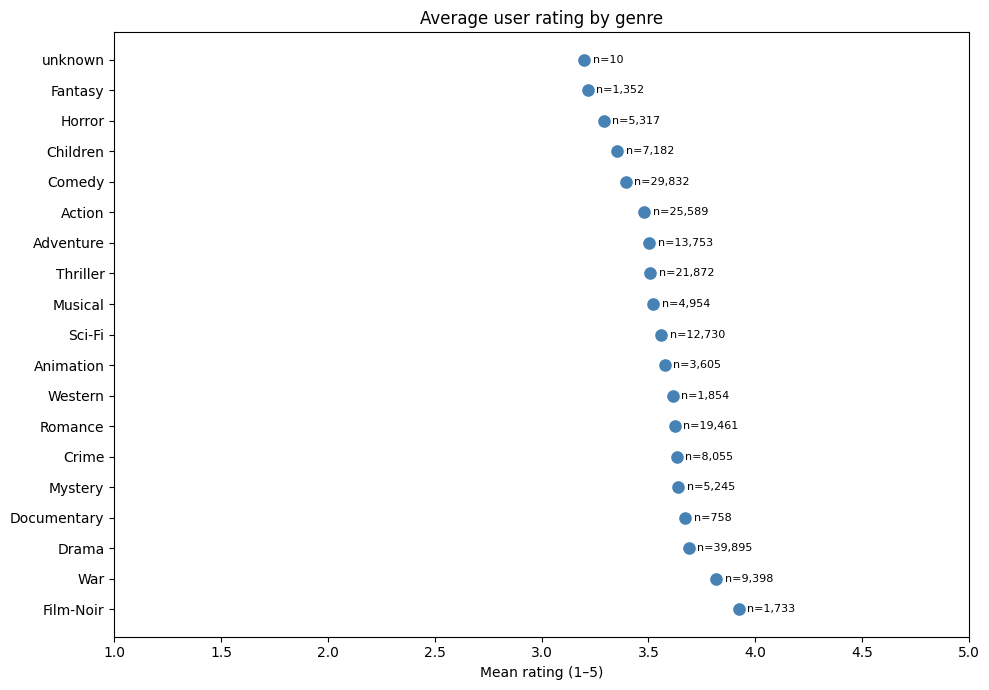

In [4]:
# Q2: your code here
# Q2: Attach each rating to every assigned genre

rating_genres = df.assign(
    genre=df["genres"].str.split("|", regex=False)
).explode("genre")

# Calculate genre statistics
q2 = (
    rating_genres.groupby("genre")
    .agg(
        mean_rating=("rating", "mean"),
        n_ratings=("rating", "size"),
        n_movies=("movie_id", "nunique"),
        std_rating=("rating", "std")
    )
    .sort_values("mean_rating", ascending=False)
)

# Display genre averages and sample sizes
display(
    q2[
        ["mean_rating", "n_ratings", "n_movies"]
    ].round(3)
)

# Create dot plot
fig, ax = plt.subplots(figsize=(10, 7))

p = q2.reset_index()

ax.scatter(
    p["mean_rating"],
    p["genre"],
    s=65,
    color="steelblue"
)

ax.set(
    xlim=(1, 5),
    xlabel="Mean rating (1–5)",
    ylabel="",
    title="Average user rating by genre"
)

# Add sample-size labels
for _, row in p.iterrows():
    ax.text(
        row["mean_rating"] + .04,
        row["genre"],
        f'n={row["n_ratings"]:,}',
        va="center",
        fontsize=8
    )

ax.set_xlim(1, 5)

plt.tight_layout()
plt.show()


**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

I found that Film-Noir has the highest average rating of 3.922 out of 5, based on 1,733 ratings from 24 movies. War comes second with an average of 3.816 from 9,398 ratings, followed by Drama with 3.687 from 39,895 ratings. I also found that the unknown category has the lowest average rating of 3.200, but it has only 10 ratings from 2 movies. Among the named genres, Fantasy has the lowest average rating of 3.215 from 1,352 ratings, so I think checking the number of ratings is important before making conclusions.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

I calculate the average rating for each release year. I also create a second chart showing how many ratings each year has, so I can judge whether the averages are supported by enough observations.

Release years represented: 71
Rating rows with known release year: 99970
Release years represented by <100 ratings: 13
Selected year results:


,mean_rating,n_ratings,n_movies
year,,,
1922.0,3.556,54,1
1926.0,3.000,2,1
1942.0,4.398,261,2
1972.0,4.216,468,3
1977.0,4.142,818,4
1980.0,3.874,1114,8
1994.0,3.420,9034,237
1995.0,3.415,12389,294
1996.0,3.311,18744,297


Means by release decade:


,mean,size
decade,,
1920.0,3.536,56
1930.0,3.925,1496
1940.0,4.011,2249
1950.0,3.938,3527
1960.0,3.877,3909
1970.0,3.873,6448
1980.0,3.767,12833
1990.0,3.390,69452


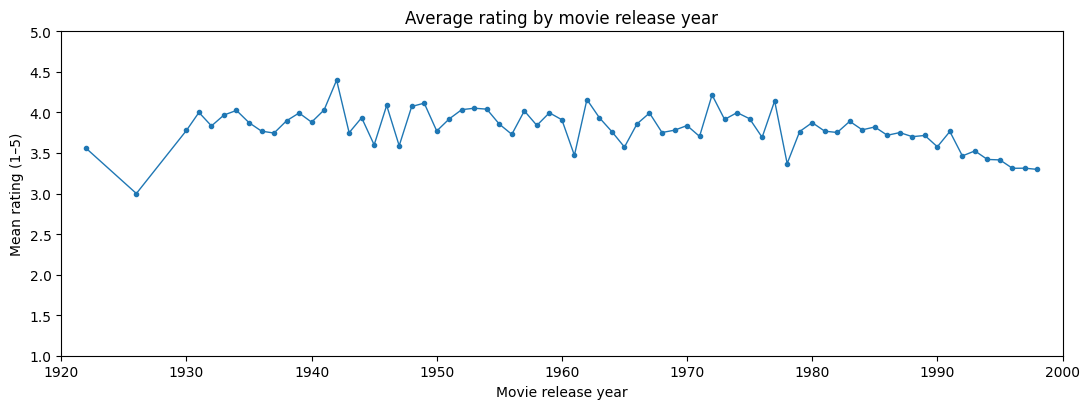

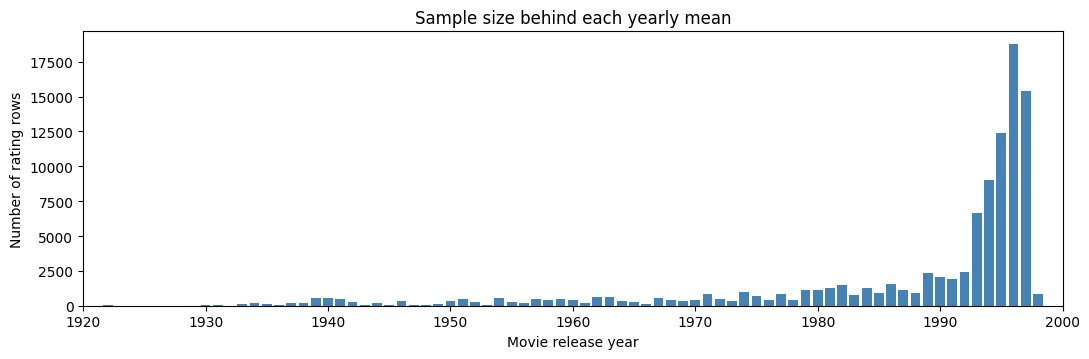

In [5]:
# Q3: Group ratings by each movie's RELEASE year,
# not the year the rating was submitted

q3 = (
    df.dropna(subset=["year"])
    .groupby("year")
    .agg(
        mean_rating=("rating", "mean"),
        n_ratings=("rating", "size"),
        n_movies=("movie_id", "nunique")
    )
    .sort_index()
)

# Display summary information
print("Release years represented:", len(q3))

print(
    "Rating rows with known release year:",
    int(q3["n_ratings"].sum())
)

print(
    "Release years represented by <100 ratings:",
    int((q3["n_ratings"] < 100).sum())
)

# Display selected release years
print("Selected year results:")

display(
    q3.loc[
        q3.index.isin([
            1922, 1926, 1942, 1972, 1977,
            1980, 1994, 1995, 1996, 1997, 1998
        ])
    ].round(3)
)

# Average ratings by release decade
print("Means by release decade:")

display(
    df.dropna(subset=["year"])
    .groupby("decade")["rating"]
    .agg(["mean", "size"])
    .round(3)
)

# Chart 1: Average rating by movie release year
fig, ax = plt.subplots(figsize=(11, 4.2))

ax.plot(
    q3.index,
    q3["mean_rating"],
    marker="o",
    markersize=3,
    linewidth=1
)

ax.set(
    xlim=(1920, 2000),
    ylim=(1, 5),
    xlabel="Movie release year",
    ylabel="Mean rating (1–5)",
    title="Average rating by movie release year"
)

plt.tight_layout()
plt.show()

# Chart 2: Number of ratings by release year
fig, ax = plt.subplots(figsize=(11, 3.7))

ax.bar(
    q3.index,
    q3["n_ratings"],
    width=0.8,
    color="steelblue"
)

ax.set(
    xlim=(1920, 2000),
    xlabel="Movie release year",
    ylabel="Number of rating rows",
    title="Sample size behind each yearly mean"
)

plt.tight_layout()
plt.show()


**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

I found that older movies generally have higher average ratings than newer movies in this dataset, although the ratings change across individual release years. Movies released in the 1940s have an average rating of 4.011 from 2,249 ratings, while movies from the 1980s average 3.767 from 12,833 ratings and movies from the 1990s average 3.390 from 69,452 ratings. I also noticed that some release years have very few ratings, such as 1926, which has only 2 ratings. Because of this, I would be careful when comparing yearly averages since years with fewer ratings may give less reliable results.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

I calculate the mean rating for each movie and rank the movies after applying the minimum-rating requirement.

In [6]:
# Q4: Calculate movie ratings first,
# then apply the minimum-rating requirement

movie_ratings = (
    df.groupby(["movie_id", "title"], as_index=False)
    .agg(
        mean_rating=("rating", "mean"),
        n_ratings=("rating", "size")
    )
)

# Function to identify top five movies
def top_movies(min_ratings):

    return (
        movie_ratings[
            movie_ratings["n_ratings"] >= min_ratings
        ]
        .sort_values(
            ["mean_rating", "n_ratings", "title"],
            ascending=[False, False, True]
        )
        .head(5)[
            ["title", "mean_rating", "n_ratings"]
        ]
        .reset_index(drop=True)
    )

# Calculate top five lists
top50 = top_movies(50)
top150 = top_movies(150)

# Count eligible movies
print(
    f"Movies eligible with ≥50 ratings: "
    f"{(movie_ratings.n_ratings >= 50).sum()}"
)

print(
    f"Movies eligible with ≥150 ratings: "
    f"{(movie_ratings.n_ratings >= 150).sum()}"
)

# Display top five with at least 50 ratings
print("\nTop five with at least 50 ratings:")

display(
    top50.round({"mean_rating": 3})
)

# Display top five with at least 150 ratings
print("\nTop five with at least 150 ratings:")

display(
    top150.round({"mean_rating": 3})
)

# Find movies that disappear or enter the top five
print(
    "\nDrop out:",
    sorted(set(top50.title) - set(top150.title))
)

print(
    "Enter:",
    sorted(set(top150.title) - set(top50.title))
)


Movies eligible with ≥50 ratings: 603
Movies eligible with ≥150 ratings: 203

Top five with at least 50 ratings:


,title,mean_rating,n_ratings
0,"Close Shave, A (1995)",4.491,112
1,Schindler's List (1993),4.466,298
2,"Wrong Trousers, The (1993)",4.466,118
3,Casablanca (1942),4.457,243
4,Wallace & Gromit: The Best of Aardman Animatio...,4.448,67



Top five with at least 150 ratings:


,title,mean_rating,n_ratings
0,Schindler's List (1993),4.466,298
1,Casablanca (1942),4.457,243
2,"Shawshank Redemption, The (1994)",4.445,283
3,Rear Window (1954),4.388,209
4,"Usual Suspects, The (1995)",4.386,267



Drop out: ['Close Shave, A (1995)', 'Wallace & Gromit: The Best of Aardman Animation (1996)', 'Wrong Trousers, The (1993)']
Enter: ['Rear Window (1954)', 'Shawshank Redemption, The (1994)', 'Usual Suspects, The (1995)']


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

I found that with a minimum of 50 ratings, the top five movies are A Close Shave (4.491, 112 ratings), Schindler's List (4.466, 298 ratings), The Wrong Trousers (4.466, 118 ratings), Casablanca (4.457, 243 ratings), and Wallace & Gromit: The Best of Aardman Animation (4.448, 67 ratings).

When I increased the minimum to 150 ratings, the top five changed to Schindler's List (4.466, 298 ratings), Casablanca (4.457, 243 ratings), The Shawshank Redemption (4.445, 283 ratings), Rear Window (4.388, 209 ratings), and The Usual Suspects (4.386, 267 ratings).

I noticed that A Close Shave, The Wrong Trousers, and Wallace & Gromit dropped out of the top five because they had fewer than 150 ratings. I think increasing the minimum makes the rankings depend on a larger number of ratings and reduces the influence of movies with smaller samples.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

Question: How do average ratings change across viewer ages for four selected genres?
I compare Action, Comedy, Drama, and Film-Noir across different age groups.

genre,Action,Comedy,Drama,Film-Noir
age_group,,,,
<18,3.568,3.157,3.594,3.500
18–24,3.444,3.340,3.641,3.787
25–34,3.437,3.378,3.647,3.871
35–44,3.531,3.434,3.743,3.990
45–54,3.563,3.477,3.762,4.070
55+,3.588,3.557,3.745,4.012


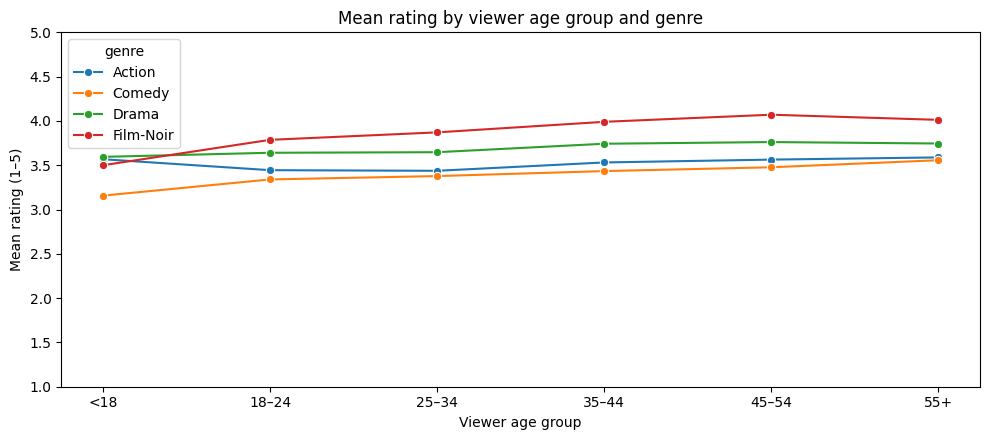

Pearson correlation: 0.43
Spearman correlation: 0.503


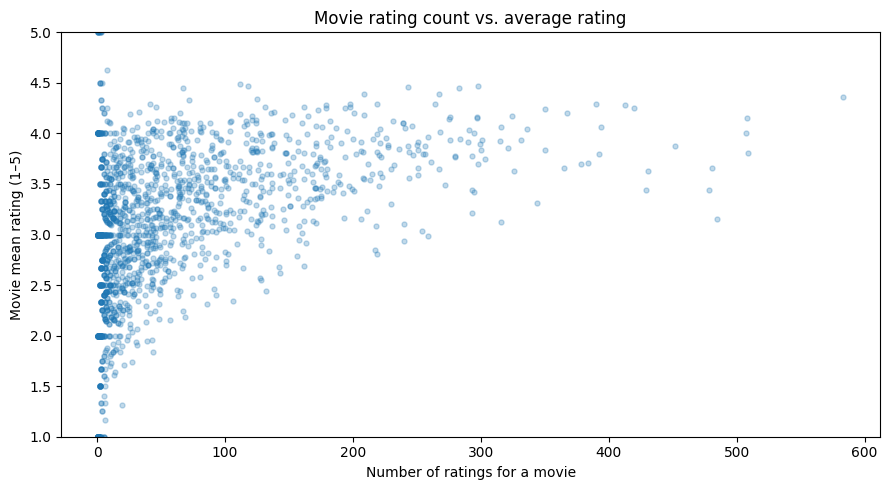

In [7]:
# Select four genres for analysis
age_data = rating_genres[
    rating_genres["genre"].isin([
        "Comedy", "Drama", "Action", "Film-Noir"
    ])
].copy()

# Create age groups
age_data["age_group"] = pd.cut(
    age_data["age"],
    [0, 17, 24, 34, 44, 54, 120],
    labels=[
        "<18", "18–24", "25–34",
        "35–44", "45–54", "55+"
    ]
)

# Calculate average ratings by age group and genre
q_age = (
    age_data.groupby(
        ["age_group", "genre"],
        observed=True
    )
    .rating.agg(["mean", "size"])
    .reset_index()
)

# Display comparison table
display(
    q_age.pivot(
        index="age_group",
        columns="genre",
        values="mean"
    ).round(3)
)

# Create line chart
fig, ax = plt.subplots(figsize=(10, 4.5))

sns.lineplot(
    data=q_age,
    x="age_group",
    y="mean",
    hue="genre",
    marker="o",
    ax=ax
)

ax.set(
    title="Mean rating by viewer age group and genre",
    xlabel="Viewer age group",
    ylabel="Mean rating (1–5)",
    ylim=(1, 5)
)

plt.tight_layout()
plt.show()


# Optional: Relationship between rating count
# and average movie rating

print(
    "Pearson correlation:",
    round(
        movie_ratings[
            ["n_ratings", "mean_rating"]
        ].corr().iloc[0, 1],
        3
    )
)

print(
    "Spearman correlation:",
    round(
        movie_ratings[
            ["n_ratings", "mean_rating"]
        ].corr(method="spearman").iloc[0, 1],
        3
    )
)

# Create scatterplot
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    movie_ratings["n_ratings"],
    movie_ratings["mean_rating"],
    alpha=0.27,
    s=13
)

ax.set(
    title="Movie rating count vs. average rating",
    xlabel="Number of ratings for a movie",
    ylabel="Movie mean rating (1–5)",
    ylim=(1, 5)
)

plt.tight_layout()
plt.show()

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

**Prompt 2**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

Prompt 1

What I asked: "Create a Streamlit dashboard using the MovieLens dataset that shows the distribution of movie genres, average ratings by genre, and how ratings differ across movie release years."

AI's first attempt: In this example, the AI created a dashboard with charts showing the number of movies in each genre, average genre ratings, and ratings by movie release year. The charts made it easier to visualize the dataset and compare different categories.

What I changed or accepted without checking: In this example, I accepted the AI's approach to counting movies across multiple genres and calculating average ratings. I focused more on getting the dashboard working than independently checking every calculation. Later, I would use my own analysis to verify whether those methods were correct.

Prompt 2

What I asked: "Add a section showing the five highest-rated movies with at least 50 ratings, compare them with movies that have at least 150 ratings, and make the dashboard interactive."

AI's first attempt: In this example, the AI created two ranking charts comparing the highest-rated movies under the two minimum-rating requirements. It also added interactive controls so users could explore the results using different rating thresholds.

What I changed or accepted without checking: In this example, I accepted the ranking approach and the interactive controls without manually verifying every movie's average rating. During my Week 6 analysis, I independently calculated the rankings and found that the results matched the dashboard. This helped me understand why checking AI-generated calculations is important.

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q2**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q3**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q4**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

### Q1. Genre breakdown

**Dashboard says:** My dashboard shows that Drama has the highest number of movies with 725, followed by Comedy with 505. Action and Thriller each have 251 movies.

**I say:** I independently calculated the genre distribution and found the same results. I counted unique movies in each genre rather than counting all the individual ratings.

**Same?** Yes.

**If different, why?** I did not find a numerical difference. Both approaches count each unique movie once within every genre it belongs to. I feel more confident about this result because my calculations reproduce the dashboard's numbers.

### Q2. Genre satisfaction

**Dashboard says:** Film-Noir has the highest average rating of 3.922, while the unknown category has the lowest average rating of 3.200.

**I say:** I found that Film-Noir has an average of 3.922 from 1,733 ratings across 24 movies. The unknown category has an average of 3.200, but it is based on only 10 ratings across 2 movies. Among actual named genres, Fantasy has the lowest average at 3.215.

**Same?** Yes, for the numerical results.

**If different, why?** I found that the dashboard calculates the averages correctly, but it does not clearly emphasize the sample sizes. I think this matters because the unknown category has very little data, so I would not confidently conclude that it is the least satisfying genre.

### Q3. Ratings over time

**Dashboard says:** My dashboard displays the average rating by movie release year, not by the year the user submitted the rating.

**I say:** I found that older movies generally have higher average ratings in this dataset. Movies released in the 1940s have an average rating of 4.011, while movies released in the 1990s have an average of 3.390.

**Same?** Partly verifiable from the PDF.

**If different, why?** I found that the dashboard and my analysis use the same movie-release-year definition. However, the PDF cuts off the later years of the line chart, so I cannot compare the entire trend from the PDF alone. I also include rating counts to make it easier to evaluate how reliable the yearly averages are.

### Q4. Best movies with a minimum-rating floor

**Dashboard says:** With at least 50 ratings, the top five movies are A Close Shave, Schindler's List, The Wrong Trousers, Casablanca, and Wallace & Gromit: The Best of Aardman Animation. When the minimum increases to 150 ratings, the top five become Schindler's List, Casablanca, The Shawshank Redemption, Rear Window, and The Usual Suspects.

**I say:** I found exactly the same top-five rankings. A Close Shave has the highest average with the 50-rating requirement at 4.491 from 112 ratings. When I increase the minimum to 150, Schindler's List becomes the highest-ranked qualifying movie with an average of 4.466 from 298 ratings.

**Same?** Yes.

**If different, why?** I found no difference in the rankings. Both approaches apply the minimum number of ratings before ranking movies by their average rating. 



## 3.3 Chart choices

**Q1**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q2**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q3**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q4**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

### Q1. Genre breakdown

**Chart the dashboard used:** Horizontal bar chart.

**Chart I used:** Horizontal bar chart with exact movie counts.

**Which communicates the answer better, and why?**

I think both charts work well because horizontal bars make it easy to compare different genres. However, I prefer my chart because I included the exact number of movies next to each bar. I also sorted the genres from highest to lowest, which makes it easier for me to identify the most and least common genres.

### Q2. Genre satisfaction

**Chart the dashboard used:** Horizontal bar chart showing average ratings by genre.

**Chart I used:** Dot plot showing the average rating and the number of ratings for each genre.

**Which communicates the answer better, and why?**

I prefer my dot plot because the average ratings are relatively close together, and I can compare them more clearly. I also added the number of ratings for each genre, which helps me understand how much data supports each result. I noticed that the dashboard's chart is partly cut off in the PDF, making some values difficult to compare.

### Q3. Ratings over time

**Chart the dashboard used:** Line chart showing mean ratings by movie release year.

**Chart I used:** Line chart showing mean ratings and a separate bar chart displaying the number of ratings in each release year.

**Which communicates the answer better, and why?**

I think both charts show the overall rating trend, but I prefer using my two charts together. I can see how ratings change across release years while also checking how many observations support each average. I believe this is important because some release years have only a few ratings, which can make their averages less reliable.

### Q4. Best movies

**Chart the dashboard used:** Two side-by-side horizontal bar charts with ranking tables.

**Chart I used:** Two tables showing movie titles, average ratings, and number of ratings.

**Which communicates the answer better, and why?**

I prefer my tables because I can read the full movie titles and compare their exact average ratings. I also included the number of ratings for each movie, which helps explain why some movies disappear from the top five when the minimum requirement increases from 50 to 150. I found that tables communicate this information more clearly than the clipped bar charts in the PDF.

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

### 1. Who is in this data? (Sampling bias)

I found that the minimum number of ratings submitted by one user is 20, while the maximum is 737. I also noticed that all 100,000 ratings were submitted in 1997 and 1998. I think the dataset mainly represents people who were active on the MovieLens rating system during that period, rather than everyone who watches movies. Because of this, I would be careful about generalizing the results to today's audience. I believe this sampling bias could affect my Q2 results because people who choose to rate certain genres may already have a strong interest in those movies.

### 2. How sure am I about the bottom genre? (Confidence intervals)

I found that the unknown category has the lowest average rating of 3.200, but it contains only 10 ratings from 2 movies. I calculated its standard deviation as approximately 1.317.

I used the rough 95% confidence interval formula:

Mean ± 1.96 × (Standard deviation / √n)

3.200 ± 1.96 × (1.317 / √10)

**95% interval ≈ [2.384, 4.016]**

I found that the interval is quite wide, which suggests a high level of uncertainty about the category's average rating. I would not confidently say unknown is the worst genre because it contains very little information and is not a meaningful movie genre. I also recognize that ratings of the same movie may not be independent observations.

### 3. What can Q3 really say about time?

I found that the dataset contains only two different rating submission years: 1997 and 1998. Because of this, I cannot use the data to determine how people's movie preferences changed over several decades. Instead, my Q3 chart shows how users from that period rated movies released in different years. I found that movies from the 1940s have an average rating of 4.011, compared with 3.390 for movies from the 1990s. I think older movies may receive higher ratings because well-known classics are more likely to be included and selected by interested viewers.

### 4. Does "average" depend on how I calculate it?

I calculated genre averages using two approaches. First, I averaged all individual ratings within each genre. Second, I calculated each movie's average rating and then averaged those movie averages within each genre, giving every movie equal weight.

I found that Film-Noir remains the highest-rated genre with both approaches, but its average changes from 3.922 to 3.548. I also noticed that Drama drops from third to ninth place, while Musical rises from eleventh to third when movies receive equal weight.

I learned that the method used to calculate an average can change how I interpret the results. I think averaging all ratings tells me more about the ratings submitted by users, while averaging movie averages gives me a better picture of the typical rated movie within a genre.

### 5. Deployment risk

I think the most misleading conclusion a studio executive could make is that Film-Noir would be the most profitable genre to produce because it has the highest average rating of 3.922. I found that this average comes from only 1,733 ratings across 24 movies in a historical dataset. I would not use this information alone to predict profitability because the dataset does not contain information about production costs, ticket sales, or current audience demand.

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

**Where I'd override the AI:**

I would improve the dashboard by including the number of ratings and unique movies alongside each genre's average rating. I noticed that the dashboard identifies unknown as the lowest-rated category without clearly emphasizing that it is based on only 10 ratings. I would also improve the charts' formatting so that long movie titles and the full release-year trend are visible in the PDF export. My analysis includes sample sizes and more readable tables to help avoid misleading interpretations.

**Where the AI held up:**

I found that the AI-assisted dashboard made several correct analytical choices. It handled movies belonging to multiple genres properly, calculated the correct genre averages, and applied the minimum-rating requirements before ranking movies. I independently reproduced the important genre counts and top-five movie rankings, which gave me more confidence in those results.

**One sentence - Looking back at both weeks, who was driving, me or the AI, and when?**

I think the AI helped me build the dashboard quickly in Week 4, but I learned in Week 6 that I need to drive the analysis myself by verifying the calculations, choosing appropriate methods, and carefully interpreting the results.


---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week